## Kütüphaneler Veri Yükleme ve Ön işlemlerin Tekrarı

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
df = pd.read_csv('OnlineRetail.csv', encoding='ISO-8859-1', dtype={'CustomerID': str})
df= df.dropna(subset=['CustomerID'])
silinecekunitprice = df[df["UnitPrice"] <= 0].index
df=df.drop(silinecekunitprice)
df["TotalPrice"] = df["UnitPrice"] * df["Quantity"]
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], dayfirst=True, errors="coerce")
df['Year']=df['InvoiceDate'].dt.year
df['Month']=df['InvoiceDate'].dt.month.astype('Int64')
df['day']=df['InvoiceDate'].dt.day
df['DayOfWeek']=df['InvoiceDate'].dt.day_name()
df['Hour']=df['InvoiceDate'].dt.hour.astype('Int64')

# 4. RFM Müşteri Segmentasyonu

### 4.1 RFM Metriklerinin Hesaplanması

In [42]:
snapshot_date = df['InvoiceDate'].max() + pd.DateOffset(1)
rfm = df.groupby('CustomerID').agg(Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),Frequency=('InvoiceNo', 'nunique'),Monetary=('TotalPrice', 'sum'))

### 4.2 Skorlama

Quintile (5'li dilim) tabanlı RFM skorlamasında, veriler en düşükten en yükseğe 5 eşit gruba (dilime) bölünür ve 1-5 arasında puanlanır:

- **Recency (Yenilik):** Son alışveriş tarihi yakın olan müşteri daha değerlidir. Bu yüzden **küçük gün sayısı yüksek puan (5)** alır.
- **Frequency (Sıklık):** Sipariş sayısı çok olan müşteri daha değerlidir. **Yüksek sipariş sayısı yüksek puan (5)** alır.
- **Monetary (Parasal Değer):** Harcaması çok olan müşteri daha değerlidir. **Yüksek harcama yüksek puan (5)** alır.

**Concatenation**, metin değerlerini (string) **yan yana birleştirme** anlamına gelir.

Buradaki ifade, R, F ve M skorlarının matematiksel olarak toplanması ($5+4+3=12$) yerine, sayıların birer metin gibi uç uca eklenerek üç haneli tek bir kod ($543$) oluşturulmasını ifade eder.

##### Matematiksel Toplama vs. Concatenation (Birleştirme)

Bir müşterinin skorları **R = 5**, **F = 4**, **M = 3** olsun:

- **Matematiksel Toplama:** $5 + 4 + 3 = \mathbf{12}$ (Tek bir sayı elde edilir)
- **Concatenation (Birleştirme):** "5" + "4" + "3" = 543 (Üç haneli bir metin kodu elde edilir)

##### Neden Toplama Yerine Concatenation Yapılır?

Matematiksel toplama yapıldığında **bilgi kaybı** yaşanır. Örneğin **12** toplam skoruna sahip iki farklı müşteri düşünün:

1. **Müşteri A:** R=5, F=4, M=3 (Toplam = 12) $\rightarrow$ *Son zamanlarda alışveriş yapmış, aktif müşteri.*
2. **Müşteri B:** R=2, F=5, M=5 (Toplam = 12) $\rightarrow$ *Eskiden çok sık ve yüklü harcama yapmış ama uzun süredir gelmeyen, kaybetmek üzere olunan müşteri.*

Toplama yaparsanız iki müşteri de 12 puan alır ve aynı kategoride görünür. **Concatenation** kullanıldığında ise ellerinizde `"543"` ve `"255"` kodları kalır; böylece müşterilerin davranış farkını kaybetmeden:

- `"555"` $\rightarrow$ **Şampiyonlar** (Champions)
- `"111"` $\rightarrow$ **Kaybedilenler** (Lost)
- `"511"` $\rightarrow$ **Yeni Müşteriler** (New Customers)

şeklinde doğrudan segmentlere ayırabilirsiniz.

In [43]:
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5])

rfm_score = rfm['RFM_Score'] = (rfm['R_Score'].astype(str)
    + rfm['F_Score'].astype(str)
    + rfm['M_Score'].astype(str))

## 4.3 K-Means ile Kümeleme

### StandardScaler

Farklı ölçeklerdeki sayısal değişkenleri, her birinin **ortalaması 0** ve **standart sapması 1** olacak şekilde standartlaştırarak modellerin (özellikle mesafe tabanlı algoritmaların) tüm özellikleri eşit ağırlıkta değerlendirmesini sağlar.

$$z = \frac{x - \mu}{\sigma}$$
* (**$x$**: Orijinal değer, **$\mu$**: Ortalama, **$\sigma$**: Standart sapma)


In [44]:
rfm = rfm[(rfm['Monetary'] > 0) & (rfm['Recency'] >= 0)]
rfm_log = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'], index=rfm.index)

### Elbow Yöntemi

K-Means algoritmasında farklı küme sayıları ($k$) için küme içi hata kareler toplamını (**WCSS**) hesaplayarak, hata düşüşünün yavaşlayıp grafiğin dirsek gibi kırıldığı noktadan **en uygun küme sayısını ($k$)** belirler.


$$\text{WCSS} = \sum_{i=1}^{k} \sum_{x \in C_i} \|x - \mu_i\|^2$$
* (**$k$**: Küme sayısı, **$C_i$**: $i$. küme, **$x$**: Veri noktası, **$\mu_i$**: Küme merkezi)


In [45]:
wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled_df)
    wcss.append(kmeans.inertia_)

In [46]:
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans_final.fit_predict(rfm_scaled_df)

cluster_summary = (rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2))
print(cluster_summary)

         Recency  Frequency  Monetary
Cluster                              
0         222.92       1.92    387.03
1          35.90      25.53  13015.19
2         134.54       6.22   1965.90
3           4.12       5.34   1456.11


In [47]:
segment_map = {0: 'Champions',1: 'Loyal',2: 'At Risk',3: 'Lost',}
rfm['Segment'] = rfm['Cluster'].map(segment_map)

segment_summary = (rfm.groupby('Segment').agg(
        Recency_Mean=('Recency', 'mean'),
        Frequency_Mean=('Frequency', 'mean'),
        Monetary_Mean=('Monetary', 'mean'),
        Customer_Count=('Recency', 'count')).reset_index())

print(segment_summary)

     Segment  Recency_Mean  Frequency_Mean  Monetary_Mean  Customer_Count
0    At Risk    134.540453        6.220874    1965.899119            1236
1  Champions    222.923878        1.915865     387.027917            1248
2       Lost      4.120567        5.340426    1456.114507             282
3      Loyal     35.903323       25.528701   13015.187583             331


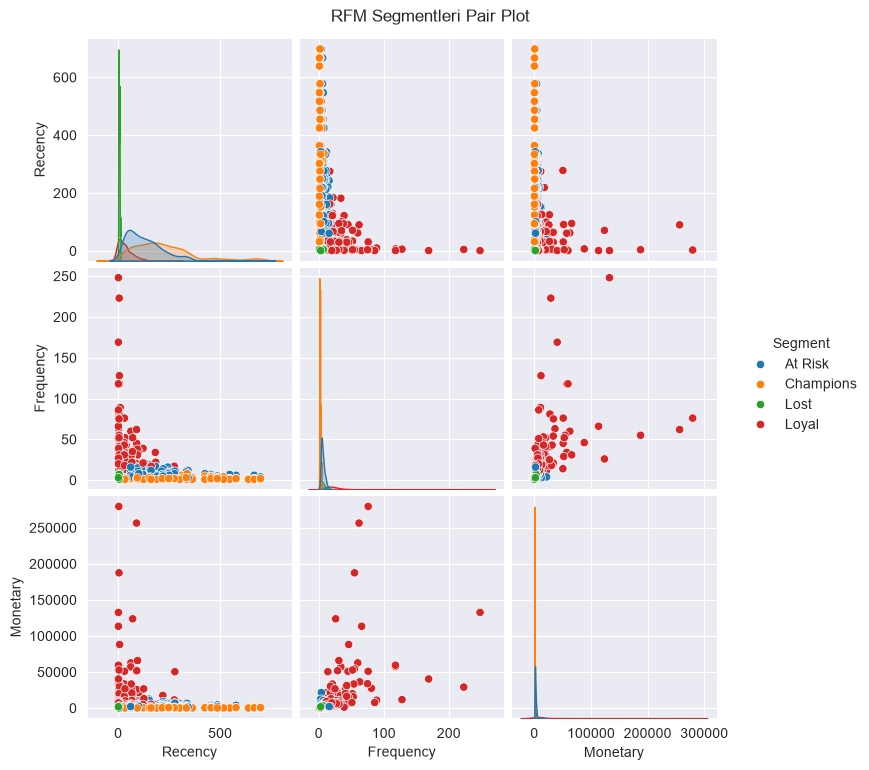

In [48]:
# Pair Plot Görselleştirmesi
sns.pairplot(
    rfm,
    vars=['Recency', 'Frequency', 'Monetary'],
    hue='Segment',
    diag_kind='kde')

plt.suptitle('RFM Segmentleri Pair Plot', y=1.02)
plt.savefig("rfm_clusters.png", bbox_inches='tight', dpi=300)
plt.show()

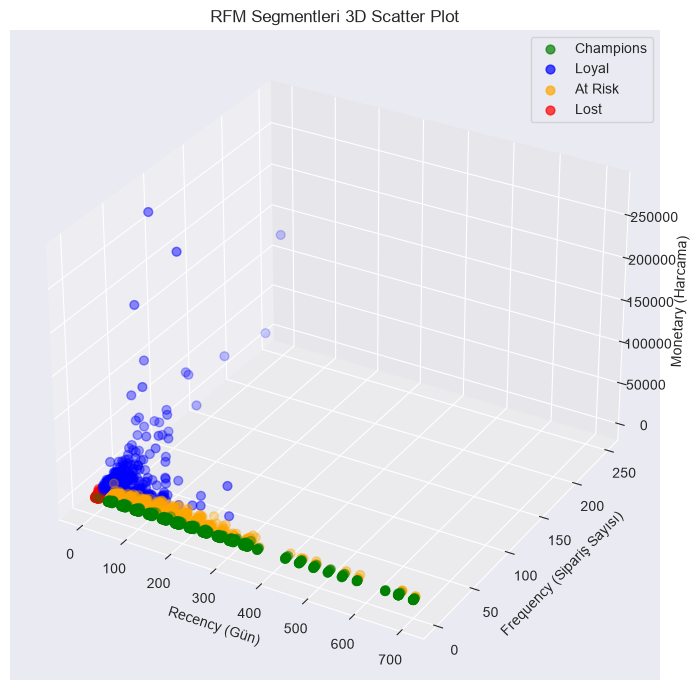

In [49]:
# 3D Grafik Scatter Plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
colors = {'Champions': 'green','Loyal': 'blue','At Risk': 'orange','Lost': 'red'}

for segment, color in colors.items():
    subset = rfm[rfm['Segment'] == segment]
    ax.scatter(subset['Recency'],subset['Frequency'],subset['Monetary'],c=color,label=segment,s=40,alpha=0.7)

ax.set_xlabel('Recency (Gün)')
ax.set_ylabel('Frequency (Sipariş Sayısı)')
ax.set_zlabel('Monetary (Harcama)')
ax.set_title('RFM Segmentleri 3D Scatter Plot')
ax.legend()

plt.tight_layout()
plt.show()

In [50]:
rfm.to_csv('customer_segments.csv')